####  Actividad 3 CAMILO LOVERA ####

In [76]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# Ver 10 columnas
pd.set_option('display.max_columns', 10)

# Cargar datos
delitos = pd.read_csv("delitos_puerto_montt_2024.csv", encoding="ISO-8859-1", sep=";")

# Renombrar columnas
delitos = delitos.rename(columns={'A¥O': 'AÑO'})
delitos['AÑO'] = delitos['AÑO'].ffill()
delitos.columns = delitos.columns.str.replace("??", " ", regex=False)


# Asegurar que AÑO y MES sean enteros
#delitos['AÑO'] = delitos['AÑO'].astype(int)
delitos['MES'] = delitos['MES'].astype(int)

# Crear una columna de periodo YYYYMM para predecir secuencialmente
delitos['PERIODO'] = delitos['AÑO'] * 100 + delitos['MES']

print(delitos)


        AÑO  MES   Femicidio   Femicidio no ¡ntimo   Suicidio femicida  ...  \
0    2005.0    1           0                     0                   0  ...   
1    2005.0    2           0                     0                   0  ...   
2    2005.0    3           0                     0                   0  ...   
3    2005.0    4           0                     0                   0  ...   
4    2005.0    5           0                     0                   0  ...   
..      ...  ...         ...                   ...                 ...  ...   
235  2024.0    8           0                     0                   0  ...   
236  2024.0    9           0                     0                   0  ...   
237  2024.0   10           0                     0                   0  ...   
238  2024.0   11           0                     0                   0  ...   
239  2024.0   12           0                     0                   0  ...   

      Otras incivilidades   Abigeato   Robo frustra

In [77]:
# Periodo
X = delitos[['PERIODO']]

# Todas las columnas de delitos, excepto AÑO, MES, PERIODO
y = delitos.drop(columns=['AÑO', 'MES', 'PERIODO'])

# Dividir en entrenamiento y testeo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Testeo:", X_test.shape, y_test.shape)


Entrenamiento: (192, 1) (192, 37)
Testeo: (48, 1) (48, 37)


In [78]:
# Random Forest Regressor para cada delito
modelo = RandomForestRegressor(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [79]:
# Evaluación del Entrenamiento con el modelo
from sklearn.metrics import mean_squared_error, r2_score

y_predicted = modelo.predict(X_train)
rmse = np.sqrt(mean_squared_error(y_train, y_predicted))
r2 = r2_score(y_train, y_predicted)

print("Rendimiento del conjunto de Entrenamiento")
print("RMSE: {}".format(rmse))
print("R2: {}".format(r2))

Rendimiento del conjunto de Entrenamiento
RMSE: 6.654169087092369
R2: 0.9110466655395238


In [80]:
# Estimación del siguiente período
proximo_periodo = pd.DataFrame(
    [[delitos['PERIODO'].max() + 1]],
    columns=X_train.columns
)

# Hacer predicción
prediccion = modelo.predict(proximo_periodo)
pred = pd.DataFrame(prediccion, columns=y.columns, index=['Predicción'])
print(pred.T.sort_values(by='Predicción', ascending=False).head(40))

                                             Predicción
Violencia intrafamiliar a mujer               602.92000
Robos en lugar no habitado                    175.18000
Robo en lugar habitado                        143.22000
Violencia intrafamiliar a hombre              140.72000
Robo de objetos de o desde veh¡culo           128.62000
Otras infracciones a la ley de armas          126.28000
Robos con violencia o intimidaci¢n             94.26000
Comercio ilegal                                64.98000
Animales sueltos en la v¡a p£blica             62.94000
Otras incivilidades                            62.52000
Abusos sexuales                                55.38000
Ofensas al pudor                               42.32000
Microtr fico de sustancias                     36.76000
Violencia intrafamiliar no clasificada         33.94000
Abigeato                                       31.44000
Otros delitos sexuales                         27.36000
Violencia intrafamiliar a adulto mayor         2

In [81]:
top_5 = pred_df.T.sort_values(by='Predicción', ascending=False).head(5)
print("Top 5 delitos con mayor predicción para el siguiente período:")
print(top_5)


Top 5 delitos con mayor predicción para el siguiente período:
                                       Predicción
??Violencia intrafamiliar a mujer          602.92
??Robos en lugar no habitado               175.18
??Robo en lugar habitado                   143.22
??Violencia intrafamiliar a hombre         140.72
??Robo de objetos de o desde veh¡culo      128.62


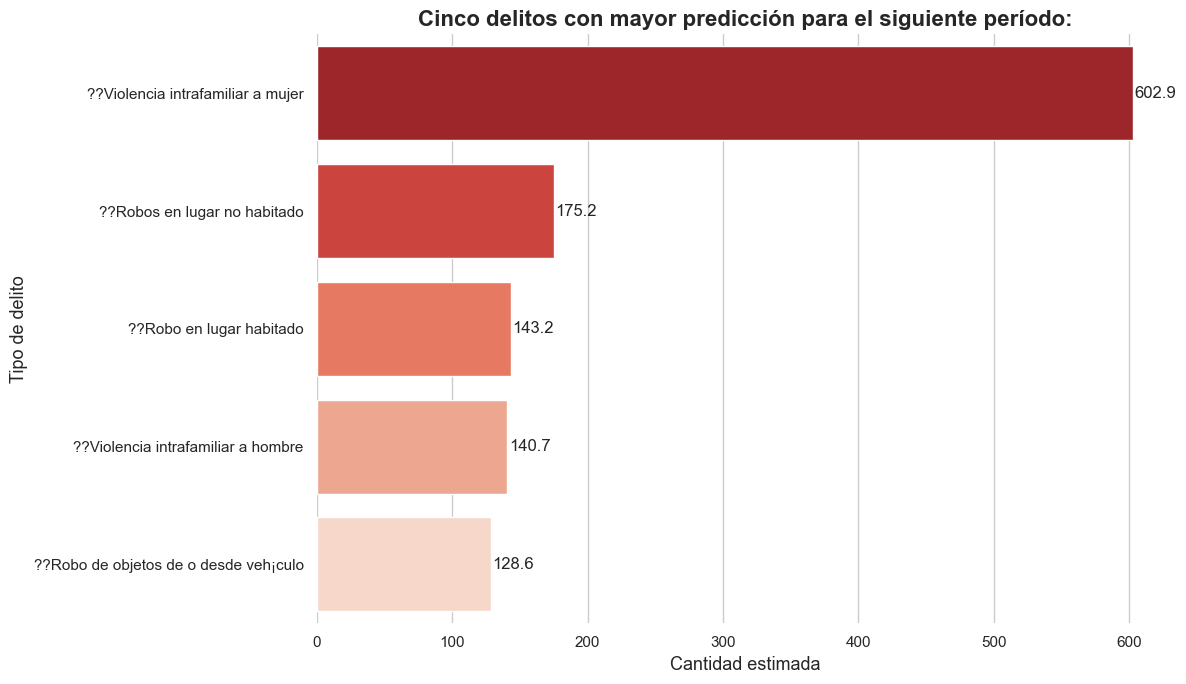

In [82]:
# DataFrame con un índice como columna para usarlo como hue
top_5_reset = top_5.reset_index().rename(columns={'index': 'Delito'})

plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Creamos el gráfico
ax = sns.barplot(
    data=top_5_reset,
    x='Predicción',
    y='Delito',
    hue='Delito',
    dodge=False,
    palette="Reds_r",
    legend=False  
)

# Título y ejes
plt.title("Cinco delitos con mayor predicción para el siguiente período:", fontsize=16, weight='bold')
plt.xlabel("Cantidad estimada", fontsize=13)
plt.ylabel("Tipo de delito", fontsize=13)

# Mostrar los valores sobre cada barra
for i, row in top_5_reset.iterrows():
    ax.text(row['Predicción'] + 1, i, f"{row['Predicción']:.1f}", va='center', fontsize=12)


sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()
